<div dir="rtl" style="text-align: right;">

# پروژه دوم: پیش‌بینی و تشخیص تصادف رانندگی با استفاده از یادگیری عمیق

## معرفی پروژه

هدف این پروژه طراحی و پیاده‌سازی یک مدل یادگیری عمیق برای تحلیل ویدئوهای رانندگی و پیش‌بینی یا تشخیص وقوع تصادف است.

در این پروژه از اطلاعات تصویری و زمانی ویدئوها استفاده می‌کنیم تا مدل بتواند علاوه بر بررسی محتوای هر فریم، تغییرات صحنه را در طول زمان نیز یاد بگیرد.

## ایده اصلی پروژه

برای انجام این کار، از ترکیب دو معماری یادگیری عمیق استفاده می‌کنیم:

**۱. CNN و مدل ResNet18**

شبکه CNN برای استخراج ویژگی‌های تصویری از فریم‌های ویدئو استفاده می‌شود. در این پروژه از مدل از پیش آموزش‌دیده ResNet18 به‌عنوان استخراج‌کننده ویژگی استفاده می‌کنیم.

**۲. LSTM و معماری ChainLSTM**

پس از استخراج ویژگی‌های تصویری، آن‌ها را به مدل LSTM می‌دهیم تا ارتباط بین فریم‌های متوالی و تغییرات زمانی صحنه را یاد بگیرد.

به این ترتیب مدل می‌تواند الگوهای تصویری و زمانی مرتبط با تصادف را شناسایی کند.

## مراحل انجام پروژه

۱. دریافت دیتاست و بررسی اطلاعات ویدئوها

۲. استخراج فریم از ویدئوها

۳. استخراج ویژگی‌های تصویری با استفاده از ResNet18

۴. آماده‌سازی توالی ویژگی‌ها برای ورود به شبکه

۵. ساخت مدل ChainLSTM

۶. آموزش مدل و تنظیم پارامترهای آن

۷. ارزیابی عملکرد مدل با معیارهای مختلف

۸. مقایسه نتایج پیش‌بینی قبل و تشخیص بعد از وقوع تصادف

## ابزارها و کتابخانه‌ها

- Python
- PyTorch
- Torchvision
- NumPy
- Pandas
- Scikit-learn
- Matplotlib

## هدف نهایی

در پایان پروژه، عملکرد مدل را بررسی می‌کنیم تا مشخص شود تا چه اندازه می‌تواند الگوهای مرتبط با تصادف را از ویدئوهای رانندگی یاد بگیرد و در تشخیص یا پیش‌بینی وقوع آن موفق عمل کند.

</div>

In [37]:
!pip -q install huggingface_hub opencv-python-headless

In [38]:
import os, time, copy, warnings
import numpy as np, pandas as pd, cv2, torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from huggingface_hub import HfApi, hf_hub_download, login
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, roc_auc_score, roc_curve,
                             confusion_matrix, average_precision_score)

warnings.filterwarnings("ignore")
login()

REPO = "nexar-ai/nexar_collision_prediction"
STEP, SIZE, N_GRID = 0.5, 224, 120
NBLK, BLK = 3, 20
PROJ, HID, DROP = 128, 64, 0.3
H_BEFORE, H_DET = 3, 6
SEEDS = 5

BASE = "/content" if os.path.isdir("/content") else "/kaggle/working"
FEAT_DIR, TMP_DIR, FIG_DIR = f"{BASE}/feats_hf", f"{BASE}/tmp_videos", f"{BASE}/figs"
for d in (FEAT_DIR, TMP_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


<div dir="rtl" style="text-align: right;">

##  وارد کردن کتابخانه‌ها و تنظیم تنظیمات اولیه

در این سلول کتابخانه‌هایی را که در طول پروژه به آن‌ها نیاز داریم وارد می‌کنیم.

همچنین تنظیمات اولیه پروژه را مشخص می‌کنیم.

### انتخاب دستگاه پردازشی

یکی از مهم‌ترین قسمت‌ها، انتخاب دستگاه پردازشی است:

- اگر GPU در دسترس باشد، از آن برای محاسبات استفاده می‌کنیم.
- در غیر این صورت، محاسبات روی CPU انجام می‌شوند.

استفاده از GPU باعث می‌شود عملیات مربوط به شبکه‌های عصبی سریع‌تر انجام شوند.

### تنظیم Seed

با تعیین Seed تلاش می‌کنیم نتایج اجرای پروژه تا حد امکان قابل تکرار باشند.

چون در یادگیری ماشین برخی عملیات مانند تقسیم داده‌ها و مقداردهی اولیه وزن‌ها تصادفی هستند، ثابت کردن Seed به مقایسه منصفانه‌تر آزمایش‌ها کمک می‌کند.

</div>

In [ ]:
def stem(p):
    return os.path.splitext(os.path.basename(str(p)))[0]

repo_files = HfApi().list_repo_files(REPO, repo_type="dataset")

train_videos = sorted(f for f in repo_files if f.startswith("train/") and f.endswith(".mp4"))
meta_files = sorted(f for f in repo_files if f.startswith("train/") and f.endswith("metadata.csv"))
meta = pd.concat([
    pd.read_csv(hf_hub_download(REPO, m, repo_type="dataset")).assign(folder=m.split("/")[1])
    for m in meta_files
])
meta["stem"] = meta["file_name"].map(stem)
info = meta.set_index(["folder", "stem"])

df_tr = pd.DataFrame({"repo_path": train_videos})
df_tr["folder"] = df_tr["repo_path"].str.split("/").str[1]
df_tr["stem"] = df_tr["repo_path"].map(stem)
df_tr["target"] = (df_tr["folder"] == "positive").astype(int)
df_tr["time_of_event"] = info["time_of_event"].reindex(list(zip(df_tr["folder"], df_tr["stem"]))).values
df_tr["tta"] = np.nan
df_tr["split"] = "train"
df_tr["npz"] = [f"{FEAT_DIR}/{t}_{s}.npz" for t, s in zip(df_tr["target"], df_tr["stem"])]  # same names as before
assert ((df_tr["target"] == 1) & df_tr["time_of_event"].isna()).sum() == 0

test_videos = sorted(f for f in repo_files if f.startswith("test") and f.endswith(".mp4"))
test_csvs = sorted(f for f in repo_files if f.startswith("test") and f.endswith("metadata.csv"))
print("test videos:", len(test_videos), "| test csv:", test_csvs)
assert test_videos and test_csvs, "No test videos / metadata found: print(repo_files[:50]) and check folder names"

tmeta = pd.concat([
    pd.read_csv(hf_hub_download(REPO, m, repo_type="dataset")).assign(folder=m.split("/")[0])
    for m in test_csvs
], ignore_index=True)
print("test columns:", list(tmeta.columns))

FILE_COL = "file_name" if "file_name" in tmeta.columns else next(
    c for c in tmeta.columns if tmeta[c].astype(str).str.endswith(".mp4").any())
LABEL_COL = None  

LABEL_COL = "time_of_event"

assert LABEL_COL in tmeta.columns, "time_of_event column not found!"

tmeta["stem"] = tmeta[FILE_COL].map(stem)
tinfo = tmeta.set_index(["folder", "stem"])
assert tinfo.index.is_unique, "duplicate (folder, stem) in test metadata"

df_te = pd.DataFrame({"repo_path": test_videos})
df_te["folder"] = df_te["repo_path"].str.split("/").str[0]
df_te["stem"] = df_te["repo_path"].map(stem)
keys = list(zip(df_te["folder"], df_te["stem"]))
event_time = tinfo["time_of_event"].reindex(keys)

lab = event_time.notna().astype(int)
df_te["target"] = lab.values
df_te["tta"] = (tinfo["time_to_accident"].reindex(keys).values
                if "time_to_accident" in tinfo.columns else np.nan)
df_te["time_of_event"] = np.nan
df_te["split"] = "test"

unl = df_te["target"].isna().sum()
if unl:
    print(f"WARNING: {unl} test videos have no label -> dropped")
df_te = df_te.dropna(subset=["target"]).copy()
df_te["target"] = df_te["target"].astype(int)
if df_te["tta"].max() > 10:            
    df_te["tta"] = df_te["tta"] / 1000.0
df_te["npz"] = [f"{FEAT_DIR}/te_{f}_{s}.npz" for f, s in zip(df_te["folder"], df_te["stem"])]

df = pd.concat([df_tr, df_te], ignore_index=True)
print(len(df_tr), "train |", len(df_te), "test | test labels:", df_te["target"].value_counts().to_dict())
print(df_te.groupby("tta", dropna=False)["target"].agg(["count", "mean"]))

test videos: 1344 | test csv: ['test-private/negative/metadata.csv', 'test-private/positive/metadata.csv', 'test-public/negative/metadata.csv', 'test-public/positive/metadata.csv']
test columns: ['file_name', 'time_of_event', 'time_of_alert', 'light_conditions', 'weather', 'scene', 'time_to_accident', 'folder']
1500 train | 1344 test | test labels: {0: 672, 1: 672}
     count  mean
tta             
0.5    568   0.5
1.0    464   0.5
1.5    312   0.5


<div dir="rtl" style="text-align: right;">

##  دریافت دیتاست و بررسی اطلاعات ویدئوها

در این مرحله دیتاست پروژه را دریافت می‌کنیم.

دیتاست شامل ویدئوهای رانندگی است که بعضی از آن‌ها دارای تصادف هستند و بعضی دیگر بدون تصادف‌اند.

علاوه بر خود ویدئوها، یک فایل اطلاعاتی یا Metadata نیز داریم.

### Metadata چیست؟

Metadata اطلاعات توصیفی مربوط به هر ویدئو را نگهداری می‌کند.

یکی از ستون‌های مهم آن `time_of_event` است.

این ستون زمان وقوع تصادف را مشخص می‌کند:

- اگر مقدار آن `NaN` باشد، یعنی در آن ویدئو تصادفی ثبت نشده است.
- اگر مقدار عددی داشته باشد، زمان وقوع تصادف در ویدئو مشخص شده است.

بنابراین از این ستون می‌توان برای تعیین برچسب ویدئوها استفاده کرد.

### هدف این مرحله

در این قسمت اطلاعات ویدئوها را می‌خوانیم و ساختار دیتاست را بررسی می‌کنیم تا برای استخراج ویژگی‌ها آماده شویم.

</div>

In [40]:
resnet = torchvision.models.resnet18(weights="IMAGENET1K_V1").to(device).eval()
for p in resnet.parameters():
    p.requires_grad = False
MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def read_grid(path):
    cap = cv2.VideoCapture(path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    if not fps or fps != fps or fps < 1:
        fps = 30.0
    want = np.round(np.arange(N_GRID) * STEP * fps).astype(int)
    need, last_needed = set(want.tolist()), int(want.max())
    got, k, last_ok = {}, 0, -1
    while k <= last_needed:
        if k in need:
            ok, fr = cap.read()
            if not ok:
                break
            got[k] = cv2.resize(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), (SIZE, SIZE), interpolation=cv2.INTER_AREA)
        elif not cap.grab():
            break
        last_ok = k
        k += 1
    cap.release()
    out = np.zeros((N_GRID, SIZE, SIZE, 3), np.uint8)
    prev = None
    for j, f in enumerate(want):
        if int(f) in got:
            prev = got[int(f)]
        if prev is not None:
            out[j] = prev
    return out, int(max((want <= last_ok).sum(), 2))

@torch.no_grad()
def l3p2_feats(x):
    x = (x.to(device).permute(0, 3, 1, 2).float() / 255.0 - MEAN) / STD
    with torch.autocast("cuda", dtype=torch.float16, enabled=(device == "cuda")):
        x = resnet.maxpool(resnet.relu(resnet.bn1(resnet.conv1(x))))
        x = resnet.layer3(resnet.layer2(resnet.layer1(x)))
    return F.adaptive_avg_pool2d(x.float(), 2).flatten(1)

def fetch_and_read(item):
    local = None
    for attempt in range(3):
        try:
            local = hf_hub_download(REPO, item[0], repo_type="dataset", local_dir=TMP_DIR)
            break
        except Exception as e:
            print("download failed:", item[0], type(e).__name__)
            time.sleep(5 * (attempt + 1))
    if local is None:
        return None
    try:
        return read_grid(local)
    except Exception as e:
        print("read failed:", item[0], type(e).__name__)
        return None
    finally:
        os.remove(local)

def has_feat(p):
    if not os.path.exists(p):
        return False
    try:
        with np.load(p) as z:
            return "l3p2" in z.files
    except Exception:
        return False

todo = [(r.repo_path, r.npz) for r in df.itertuples() if not has_feat(r.npz)]
print("remaining:", len(todo), "of", len(df))

failed, t0 = [], time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    for s in range(0, len(todo), 16):
        chunk = todo[s:s + 16]
        for (rp, dst), res in zip(chunk, ex.map(fetch_and_read, chunk)):
            if res is None:
                failed.append(rp)
                continue
            frames, n = res
            tmp = dst[:-4] + "_tmp.npz"
            np.savez(tmp, n=n, l3p2=l3p2_feats(torch.from_numpy(frames)).cpu().numpy().astype(np.float16))
            os.replace(tmp, dst)
        if (s // 16) % 5 == 0:
            print(f"{min(s + 16, len(todo))}/{len(todo)}  {time.time() - t0:.0f}s")
print("failed:", len(failed))

remaining: 0 of 2844
failed: 0


<div dir="rtl" style="text-align: right;">

##  استخراج ویژگی از فریم‌های ویدئو با استفاده از ResNet18

این بخش یکی از مهم‌ترین مراحل پروژه است.

شبکه عصبی قرار نیست مستقیماً تمام پیکسل‌های ویدئو را در اختیار مدل نهایی قرار دهد. ابتدا باید از فریم‌های ویدئو ویژگی استخراج کنیم.

### مرحله اول: تبدیل ویدئو به فریم

ویدئو در واقع مجموعه‌ای از تصاویر است که با سرعت مشخصی پشت سر هم نمایش داده می‌شوند.

ما با فاصله زمانی ۰٫۵ ثانیه از ویدئو فریم استخراج می‌کنیم.

برای مثال، اگر ویدئو ۴ ثانیه باشد، فریم‌هایی از زمان‌های زیر انتخاب می‌شوند:

- ثانیه ۰
- ثانیه ۰٫۵
- ثانیه ۱
- ثانیه ۱٫۵
- و به همین ترتیب.

فریم‌ها به اندازه ۲۲۴ در ۲۲۴ تغییر داده می‌شوند تا ورودی مناسبی برای ResNet18 باشند.

### مرحله دوم: استفاده از ResNet18

از مدل از پیش آموزش‌دیده ResNet18 استفاده می‌کنیم.

این مدل قبلاً روی دیتاست ImageNet آموزش دیده است و توانایی استخراج ویژگی‌های تصویری را دارد.

به جای آموزش مجدد ResNet18، پارامترهای آن را ثابت می‌کنیم و از آن به‌عنوان استخراج‌کننده ویژگی یا Feature Extractor استفاده می‌کنیم.

### مرحله سوم: استخراج ویژگی

در این پروژه از خروجی لایه سوم ResNet18 استفاده می‌کنیم.

این خروجی اطلاعات تصویری مهمی مانند شکل‌ها، بافت‌ها و الگوهای موجود در تصویر را در خود دارد.

سپس با استفاده از Pooling ابعاد فضایی ویژگی‌ها را کاهش می‌دهیم و برای هر فریم یک بردار ویژگی با ۱۰۲۴ مقدار به دست می‌آوریم.

در نتیجه به جای ذخیره مستقیم تصویر، نمایش عددی آن را ذخیره می‌کنیم.

### چرا این کار را انجام می‌دهیم؟

پردازش مستقیم تمام پیکسل‌های تعداد زیادی فریم، محاسبات سنگینی نیاز دارد.

استخراج ویژگی باعث می‌شود اطلاعات مهم تصاویر را به شکل بردارهای عددی در اختیار شبکه زمانی قرار دهیم.

</div>

In [46]:
df = df[df["npz"].map(os.path.exists)].reset_index(drop=True)

feats, nvalid = [], []
for p in df["npz"]:
    with np.load(p) as z:
        nvalid.append(int(z["n"]))
        feats.append(z["l3p2"])
X = torch.from_numpy(np.stack(feats)).to(device)
del feats

labels = df["target"].values.astype(int)
is_tr = (df["split"] == "train").values
T = X.shape[1]
len_np = np.clip(np.array(nvalid), 2, T)
LEN = torch.as_tensor(len_np, device=device)
EV_T = df["time_of_event"].values.astype(float)
EV = np.where(is_tr & (labels == 1), np.ceil(np.nan_to_num(EV_T) / STEP), -1).astype(int)
EV = np.where(is_tr & (labels == 1), np.minimum(EV, len_np - 1), -1)

train_ids = np.where(is_tr)[0]
ext_ids = np.where(~is_tr)[0]

# Prediction: train on all train videos (85/15 train/val), test = external test set
tr_b, va_b = train_test_split(train_ids, test_size=0.15, stratify=labels[train_ids], random_state=0)
# Detection: internal split
dev_d, te_d = train_test_split(train_ids, test_size=0.2, stratify=labels[train_ids], random_state=0)
tr_d, va_d = train_test_split(dev_d, test_size=0.15, stratify=labels[dev_d], random_state=0)

SPLITS = {
    "before": dict(tr=tr_b, va=va_b, te=ext_ids, pool=EV[train_ids][labels[train_ids] == 1], external=True),
    "detect": dict(tr=tr_d, va=va_d, te=te_d, pool=EV[dev_d][labels[dev_d] == 1], external=False),
}
print("X:", tuple(X.shape))
for m, S in SPLITS.items():
    print(m, "| train:", len(S["tr"]), "| val:", len(S["va"]), "| test:", len(S["te"]))

X: (2844, 120, 1024)
before | train: 1275 | val: 225 | test: 1344
detect | train: 1020 | val: 180 | test: 300


<div dir="rtl" style="text-align: right;">

## بارگذاری ویژگی‌های استخراج‌شده و تقسیم داده‌ها

در این مرحله، ویژگی‌های تصویری استخراج‌شده توسط ResNet18 را از فایل‌های ذخیره‌شده بارگذاری می‌کنیم و داده‌ها را برای آموزش، اعتبارسنجی و آزمون آماده می‌کنیم.

**۱. بارگذاری ویژگی‌ها**

ابتدا ویدئوهایی را که استخراج ویژگی آن‌ها با موفقیت انجام شده است نگه می‌داریم. سپس ویژگی‌های ذخیره‌شده در فایل‌های NPZ را می‌خوانیم.

هر ویدئو شامل یک توالی از بردارهای ویژگی است که هر بردار معرف اطلاعات تصویری یک فریم است. همچنین تعداد فریم‌های معتبر هر ویدئو ذخیره شده است تا فریم‌های مصنوعی یا خارج از محدوده زمانی واقعی در محاسبات لحاظ نشوند.

**۲. آماده‌سازی برچسب‌ها و زمان وقوع تصادف**

برای هر ویدئو، برچسب وقوع تصادف را مشخص می‌کنیم:

- مقدار ۱: ویدئوی دارای تصادف
- مقدار ۰: ویدئوی بدون تصادف

همچنین زمان وقوع تصادف را به اندیس متناظر در توالی فریم‌ها تبدیل می‌کنیم. با توجه به اینکه هر ۰٫۵ ثانیه یک فریم نمونه‌برداری شده است، زمان وقوع تصادف بر اساس همین فاصله زمانی به اندیس تبدیل می‌شود.

**۳. تقسیم داده‌ها برای دو مسئله**

در این پروژه دو وظیفه مستقل داریم:

- **Prediction (پیش‌بینی تصادف):** مدل با داده‌های آموزشی آموزش می‌بیند، بخشی از آن‌ها برای اعتبارسنجی کنار گذاشته می‌شود و در نهایت روی مجموعه آزمون خارجی ارزیابی می‌شود.
- **Detection (تشخیص تصادف):** داده‌های آموزشی به سه بخش آموزش، اعتبارسنجی و آزمون داخلی تقسیم می‌شوند.

در هر دو حالت از تقسیم‌بندی Stratified استفاده می‌کنیم تا نسبت ویدئوهای دارای تصادف و بدون تصادف در بخش‌های مختلف تا حد امکان حفظ شود.

در نهایت، ویژگی‌ها، برچسب‌ها، طول توالی‌ها و زمان وقوع تصادف برای ورود به مدل آماده می‌شوند.

</div>

In [47]:
def feat_stats(ids):
    ids = torch.as_tensor(ids, device=device)
    real = torch.arange(T, device=device)[None, :] < LEN[ids][:, None]
    xs = X[ids][real].float()
    return xs.mean(0), xs.std(0) + 1e-6

def prep(ids, mu, sd):
    it = torch.as_tensor(np.asarray(ids), device=device)
    valid = (torch.arange(T, device=device)[None, :] < LEN[it][:, None]).float()[..., None]
    x = (X[it].float() - mu) / sd * valid
    d = torch.cat([torch.zeros_like(x[:, :1]), x[:, 1:] - x[:, :-1]], 1)
    return torch.cat([x, d], -1)

def step_targets(ids, mode):
    Y = np.zeros((len(ids), T), np.float32)
    M = np.zeros((len(ids), T), np.float32)
    for j, i in enumerate(ids):
        M[j, :len_np[i]] = 1
        if labels[i] == 1:
            e = int(EV[i])
            if mode == "before":
                M[j, e:] = 0
                Y[j, max(e - H_BEFORE, 0):e] = 1
            else:
                M[j, e] = 0
                M[j, e + H_DET + 1:] = 0
                Y[j, e + 1:e + H_DET + 1] = 1
    return torch.as_tensor(Y, device=device), torch.as_tensor(M, device=device)

class ChainLSTM(nn.Module):
    def __init__(s, d_in, nblk, blk, proj=PROJ, hid=HID, drop=DROP):
        super().__init__()
        s.W, s.blk = nblk * blk, blk
        s.proj = nn.Sequential(nn.Dropout(drop), nn.Linear(d_in, proj), nn.ReLU())
        s.lstms = nn.ModuleList([nn.LSTM(proj + (hid if i else 0), hid, batch_first=True)
                                 for i in range(nblk)])
        s.drop = nn.Dropout(drop)
        s.fc = nn.Linear(hid, 1)

    def forward(s, x):
        B, T_, _ = x.shape
        p = F.pad(s.proj(x), (0, 0, s.W - 1, 0))
        w = p.unfold(1, s.W, 1).permute(0, 1, 3, 2).reshape(B * T_, s.W, -1)
        h = None
        for i, lstm in enumerate(s.lstms):
            c = w[:, i * s.blk:(i + 1) * s.blk]
            if h is not None:
                c = torch.cat([c, h[:, None].expand(-1, s.blk, -1)], -1)
            o, _ = lstm(c)
            h = o[:, -1]
        return s.fc(s.drop(h)).view(B, T_)

def fit(mode, seed, tr, va, nblk=NBLK, blk=BLK, max_ep=40, patience=5, noise=0.1, lr=5e-4):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    mu, sd = feat_stats(tr)
    model = ChainLSTM(X.shape[-1] * 2, nblk, blk).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr, weight_decay=1e-2)
    Ytr, Mtr = step_targets(tr, mode)
    Yva, Mva = step_targets(va, mode)
    pw = float(((Mtr * (1 - Ytr)).sum() / (Mtr * Ytr).sum()).clamp(max=30))
    lossf = nn.BCEWithLogitsLoss(reduction="none", pos_weight=torch.tensor([pw], device=device))
    mloss = lambda out, Y, M: (lossf(out, Y) * M).sum() / M.sum()
    xva = prep(va, mu, sd)
    best, bad, state, best_ep = 1e9, 0, None, 0
    for ep in range(max_ep):
        model.train()
        perm = rng.permutation(len(tr))
        for i in range(0, len(perm), 32):
            b = perm[i:i + 32]
            x = prep(tr[b], mu, sd)
            x = x + noise * torch.randn_like(x)
            opt.zero_grad()
            mloss(model(x), Ytr[b], Mtr[b]).backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step()
        model.eval()
        with torch.no_grad():
            vl = mloss(model(xva), Yva, Mva).item()
        if vl < best - 1e-4:
            best, bad, state, best_ep = vl, 0, copy.deepcopy(model.state_dict()), ep + 1
        else:
            bad += 1
            if bad >= patience:
                break
    model.load_state_dict(state)
    model.eval()
    model.best_ep = best_ep
    return model, mu, sd

@torch.no_grad()
def curves(model, ids, mu, sd):
    ids = np.asarray(ids)
    out = [torch.sigmoid(model(prep(ids[i:i + 64], mu, sd))) for i in range(0, len(ids), 64)]
    return torch.cat(out).cpu().numpy() * (np.arange(T)[None, :] < len_np[ids][:, None])

```html
<div dir="rtl" style="text-align: right;">

## پیش‌پردازش ویژگی‌ها و طراحی مدل ChainLSTM

در این مرحله ویژگی‌های استخراج‌شده از فریم‌ها را برای یادگیری زمانی آماده می‌کنیم و مدل ChainLSTM را طراحی و آموزش می‌دهیم.

**۱. نرمال‌سازی ویژگی‌ها**

ابتدا میانگین و انحراف معیار ویژگی‌ها را فقط از داده‌های آموزشی محاسبه می‌کنیم. سپس ویژگی‌ها را با استفاده از این مقادیر نرمال‌سازی می‌کنیم.

این کار باعث می‌شود مقیاس ویژگی‌ها مناسب‌تر شود و فرایند آموزش شبکه پایداری بیشتری داشته باشد.

**۲. محاسبه تغییرات زمانی (Temporal Difference)**

علاوه بر ویژگی‌های اصلی هر فریم، اختلاف ویژگی آن فریم با فریم قبلی را نیز محاسبه می‌کنیم.

به این ترتیب مدل علاوه بر اطلاعات ظاهری هر فریم، اطلاعات مربوط به تغییرات بین فریم‌ها را نیز دریافت می‌کند.

در نتیجه ورودی مدل شامل دو بخش است:

- ویژگی‌های تصویری هر فریم
- تغییرات ویژگی‌ها نسبت به فریم قبلی

**۳. ساخت برچسب‌های زمانی (Step Targets)**

به جای اینکه مدل فقط برای کل ویدئو یک خروجی تولید کند، برای هر فریم یک امتیاز احتمال تصادف پیش‌بینی می‌کند.

برای این کار، برچسب‌های زمانی و ماسک معتبر بودن فریم‌ها را ایجاد می‌کنیم.

دو نوع برچسب‌گذاری داریم:

- **Prediction:** چند لحظه قبل از وقوع تصادف به‌عنوان بازه مثبت در نظر گرفته می‌شود و مدل باید وقوع تصادف را پیش‌بینی کند.
- **Detection:** چند لحظه بعد از وقوع تصادف به‌عنوان بازه مثبت در نظر گرفته می‌شود و مدل باید تصادف را تشخیص دهد.

ماسک نیز مشخص می‌کند کدام فریم‌ها باید در محاسبه خطا شرکت کنند و کدام فریم‌ها باید نادیده گرفته شوند.

**۴. معماری ChainLSTM**

مدل ChainLSTM از چند بلوک LSTM تشکیل شده است که به‌صورت زنجیره‌ای به یکدیگر متصل هستند.

ابتدا ویژگی‌های ورودی توسط یک لایه خطی به فضای ابعادی کوچک‌تری منتقل می‌شوند. سپس توالی ویژگی‌ها به بلوک‌های LSTM داده می‌شود.

در این معماری، خروجی بلوک قبلی به‌عنوان اطلاعات کمکی به بلوک بعدی منتقل می‌شود. این ارتباط به مدل کمک می‌کند اطلاعات زمانی را به‌صورت مرحله‌ای پردازش کند.

در پایان، خروجی آخرین بلوک از طریق یک لایه Fully Connected به یک مقدار تبدیل می‌شود که نشان‌دهنده امتیاز پیش‌بینی تصادف برای هر فریم است.

**۵. آموزش مدل**

برای آموزش از روش‌های زیر استفاده می‌کنیم:

- Optimizer: AdamW
- Loss Function: BCEWithLogitsLoss
- Batch Size: 32
- Learning Rate: 0.0005
- Dropout: 0.3
- Early Stopping با صبر ۵ دوره

از آنجا که تعداد فریم‌های مثبت و منفی متعادل نیست، از وزن‌دهی به کلاس مثبت (pos_weight) استفاده می‌کنیم تا مدل نسبت به فریم‌های مثبت توجه بیشتری داشته باشد.

همچنین برای جلوگیری از انفجار گرادیان از Gradient Clipping استفاده می‌کنیم و با افزودن نویز کنترل‌شده به ورودی‌ها، مقاومت مدل را افزایش می‌دهیم.

در نهایت بهترین وزن‌های مدل بر اساس خطای مجموعه اعتبارسنجی ذخیره و بازیابی می‌شوند.

</div>
```

In [48]:
AGG = "top3"  

def offsets(mode):
    return (-1, -2, -3) if mode == "before" else (1, 2, 3)

def smooth(c, k=3):
    cs = np.cumsum(np.pad(c, ((0, 0), (k, 0))), 1)
    return (cs[:, k:] - cs[:, :-k]) / k

def cut_points(ids, mode, seed, pool):
    rng = np.random.default_rng(seed)
    cut = np.zeros(len(ids), int)
    for j, i in enumerate(ids):
        if mode == "before":
            cut[j] = int(EV[i]) if labels[i] == 1 else min(int(rng.choice(pool)), int(len_np[i]))
        else:
            cut[j] = int(len_np[i])
    return np.maximum(cut, 1)

def vid_scores(cs, cut, agg="max", k=3):
    if agg == "max":
        return np.array([cs[j, :c].max() for j, c in enumerate(cut)])
    return np.array([np.sort(cs[j, :c])[-k:].mean() for j, c in enumerate(cut)])

def best_tau(yv, sv):
    taus = np.linspace(0.05, 0.99, 95)
    accs = np.array([np.mean((sv > t) == (yv == 1)) for t in taus])
    best = np.where(accs == accs.max())[0]
    return float(taus[best[len(best) // 2]])

def clip_scores(cv_, ids, offset, pool, seed=0):          # internal split (detect)
    rng = np.random.default_rng(seed)
    p, y = [], []
    for j, i in enumerate(ids):
        e = EV[i] + offset if labels[i] == 1 else rng.choice(pool) + offset
        p.append(cv_[j, int(np.clip(e, 1, len_np[i] - 1))])
        y.append(labels[i])
    return np.array(p), np.array(y)

def clip_scores_external(raw, ids, sec):                  # external test (before)
    yt_, tta = labels[ids], df["tta"].values[ids]
    last = raw[np.arange(len(ids)), len_np[ids] - 1]
    m = np.isclose(tta, sec)
    pos = m & (yt_ == 1)
    neg = (m & (yt_ == 0)) if (m & (yt_ == 0)).any() else (yt_ == 0)
    assert pos.any(), f"no positive test clips with time_to_accident={sec}"
    idx = np.where(pos | neg)[0]
    return last[idx], yt_[idx]

def evaluate(mode):
    S = SPLITS[mode]
    tr, va, te, pool = S["tr"], S["va"], S["te"], S["pool"]
    cva, cte = [], []
    for s in range(SEEDS):
        t = time.time()
        model, mu, sd = fit(mode, s, tr, va)
        cva.append(curves(model, va, mu, sd))
        cte.append(curves(model, te, mu, sd))
        print(f"[{mode}] seed {s} done in {time.time() - t:.0f}s | best epoch {model.best_ep}")
    raw_va, raw_te = np.mean(cva, 0), np.mean(cte, 0)
    cut_va = cut_points(va, mode, 1, pool)
    cut_te = np.maximum(len_np[te], 1) if S["external"] else cut_points(te, mode, 2, pool)
    yt = labels[te]
    sv_va = vid_scores(smooth(raw_va), cut_va, AGG)
    sv_te = vid_scores(smooth(raw_te), cut_te, AGG)
    tau = best_tau(labels[va], sv_va)
    acc = accuracy_score(yt, sv_te > tau)
    row = dict(mode=mode, agg=AGG,
               video_auc=roc_auc_score(yt, sv_te), video_ap=average_precision_score(yt, sv_te),
               video_acc=acc, acc_ci=1.96 * np.sqrt(acc * (1 - acc) / len(yt)), tau=tau,
               auc_max=roc_auc_score(yt, vid_scores(smooth(raw_te), cut_te, "max")),
               auc_top3=roc_auc_score(yt, vid_scores(smooth(raw_te), cut_te, "top3")))
    clip = {}
    for o in offsets(mode):
        sec = abs(o) * STEP
        if S["external"]:
            p, y = clip_scores_external(raw_te, te, sec)
        else:
            p, y = clip_scores(raw_te, te, o, pool)
        row[f"clip_auc_{sec:.1f}s"] = roc_auc_score(y, p)
        row[f"clip_acc_{sec:.1f}s"] = accuracy_score(y, p > 0.5)
        clip[o] = (p, y)
    return dict(row=row, raw=raw_te, sv=sv_te, clip=clip, cm=confusion_matrix(yt, sv_te > tau))

<div dir="rtl" style="text-align: right;">

## ارزیابی عملکرد مدل (Model Evaluation)

در این مرحله عملکرد مدل‌های آموزش‌دیده را در دو وظیفه پیش‌بینی و تشخیص تصادف بررسی می‌کنیم.

**۱. میانگین‌گیری از پیش‌بینی مدل‌ها**

برای کاهش وابستگی نتایج به مقداردهی اولیه تصادفی وزن‌ها، هر مدل را با ۵ مقدار مختلف Seed آموزش می‌دهیم.

سپس خروجی مدل‌های مختلف را میانگین می‌گیریم تا پیش‌بینی نهایی پایدارتر شود.

**۲. تبدیل خروجی فریم‌ها به امتیاز ویدئو**

مدل برای هر فریم یک احتمال تصادف تولید می‌کند. برای ارزیابی در سطح ویدئو، ابتدا احتمال‌ها را با پنجره سه‌فریمی هموار می‌کنیم.

سپس از دو روش برای محاسبه امتیاز نهایی ویدئو استفاده می‌کنیم:

- **Max:** بیشترین احتمال پیش‌بینی‌شده در ویدئو
- **Top-3:** میانگین سه احتمال بزرگ‌تر در ویدئو

در آزمایش فعلی، روش Top-3 به‌عنوان روش اصلی تجمیع انتخاب شده است.

**۳. تعیین آستانه تصمیم‌گیری (Threshold)**

برای تبدیل احتمال پیش‌بینی‌شده به برچسب نهایی، به یک آستانه نیاز داریم.

این آستانه با استفاده از مجموعه اعتبارسنجی انتخاب می‌شود تا دقت طبقه‌بندی بیشینه شود.

سپس همان آستانه برای ارزیابی مجموعه آزمون استفاده می‌شود.

**۴. معیارهای ارزیابی**

برای بررسی عملکرد مدل از معیارهای زیر استفاده می‌کنیم:

- **Video AUC:** توانایی مدل در تفکیک ویدئوهای تصادفی از ویدئوهای عادی.
- **Average Precision (AP):** بررسی کیفیت رتبه‌بندی پیش‌بینی‌های مثبت، با توجه ویژه به کلاس مثبت.
- **Accuracy:** نسبت پیش‌بینی‌های صحیح به کل پیش‌بینی‌ها.
- **Confidence Interval:** تخمین عدم‌قطعیت آماری دقت.
- **Clip AUC و Clip Accuracy:** ارزیابی مدل در یک فاصله زمانی مشخص از لحظه تصادف.

**۵. ارزیابی زمانی**

برای بررسی دقیق‌تر رفتار مدل، عملکرد آن را در فاصله‌های زمانی ۰٫۵، ۱ و ۱٫۵ ثانیه از لحظه تصادف بررسی می‌کنیم.

در حالت Prediction این فاصله‌ها مربوط به قبل از تصادف و در حالت Detection مربوط به بعد از تصادف هستند.

در پایان، ماتریس درهم‌ریختگی (Confusion Matrix) نیز برای بررسی تعداد پیش‌بینی‌های صحیح و خطاهای مدل محاسبه می‌شود.

</div>

In [49]:
TITLES = {"before": "Before crash (prediction)", "detect": "After crash (detection)"}

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(f"{FIG_DIR}/{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

def plot_roc(R):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    for ax, mode in zip(axs, R):
        r = R[mode]
        fpr, tpr, _ = roc_curve(labels[SPLITS[mode]["te"]], r["sv"])
        ax.plot(fpr, tpr, lw=2.8, label=f"Whole video (AUC={r['row']['video_auc']:.3f})")
        for o, (p, y) in r["clip"].items():
            f, t, _ = roc_curve(y, p)
            side = "before" if o < 0 else "after"
            ax.plot(f, t, lw=1.6, label=f"{abs(o) * STEP:.1f}s {side} crash (AUC={roc_auc_score(y, p):.3f})")
        ax.plot([0, 1], [0, 1], "k--", lw=1)
        ax.set_title(TITLES[mode])
        ax.set_xlabel("False positive rate")
        ax.set_ylabel("True positive rate")
        ax.legend(loc="lower right", fontsize=9)
        ax.grid(alpha=0.3)
    finish(fig, "roc")

def plot_clip_bars(R):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    secs = (0.5, 1.0, 1.5)
    x, w = np.arange(3), 0.36
    for ax, (metric, name) in zip(axs, (("auc", "AUC"), ("acc", "Accuracy"))):
        for i, mode in enumerate(R):
            vals = [R[mode]["row"][f"clip_{metric}_{s:.1f}s"] for s in secs]
            bars = ax.bar(x + (i - 0.5) * w, vals, w, label=TITLES[mode])
            ax.bar_label(bars, fmt="%.2f", fontsize=9)
        ax.set_xticks(x)
        ax.set_xticklabels([f"{s} s" for s in secs])
        ax.set_xlabel("Distance from crash")
        ax.set_ylabel(name)
        ax.set_ylim(0.4, 1.0)
        ax.set_title(f"Clip-level {name}")
        ax.legend()
        ax.grid(axis="y", alpha=0.3)
    finish(fig, "clip_metrics")

def plot_aligned(R):
    fig, axs = plt.subplots(1, 2, figsize=(12, 5))
    for ax, mode in zip(axs, R):
        S = SPLITS[mode]; te = S["te"]
        rng = np.random.default_rng(0)
        if S["external"]:
            ref, ks, xl, vl = len_np[te] - 1, np.arange(-12, 1), "Time relative to clip end (s)", "Clip end"
        else:
            ref = np.where(labels[te] == 1, EV[te], rng.choice(S["pool"], len(te)))
            ks, xl, vl = np.arange(-4, 13), "Time relative to crash (s)", "Crash"
        for name, cls in (("Crash videos", 1), ("Normal videos", 0)):
            rows = []
            for j in range(len(te)):
                if labels[te[j]] != cls:
                    continue
                idx = ref[j] + ks
                ok = (idx >= 0) & (idx < len_np[te[j]])
                rows.append(np.where(ok, R[mode]["raw"][j, np.clip(idx, 0, T - 1)], np.nan))
            rows = np.array(rows)
            m = np.nanmean(rows, 0)
            se = np.nanstd(rows, 0) / np.sqrt((~np.isnan(rows)).sum(0))
            ax.plot(ks * STEP, m, lw=2.4, label=name)
            ax.fill_between(ks * STEP, m - se, m + se, alpha=0.25)
        ax.axvline(0, color="k", ls="--", lw=1.2, label=vl)
        ax.set_title(TITLES[mode])
        ax.set_xlabel(xl)
        ax.set_ylabel("Mean predicted crash probability")
        ax.legend()
        ax.grid(alpha=0.3)
    finish(fig, "aligned_curves")

def plot_confusion(R):
    fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))
    for ax, mode in zip(axs, R):
        cm = R[mode]["cm"]
        ax.imshow(cm, cmap="Blues")
        for a in range(2):
            for b in range(2):
                ax.text(b, a, cm[a, b], ha="center", va="center", fontsize=18,
                        color="white" if cm[a, b] > cm.max() / 2 else "black")
        ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
        ax.set_xticklabels(["Normal", "Crash"]); ax.set_yticklabels(["Normal", "Crash"])
        ax.set_xlabel("Predicted"); ax.set_ylabel("True")
        ax.set_title(f"{TITLES[mode]}\nacc={R[mode]['row']['video_acc']:.3f}")
    finish(fig, "confusion")

<div dir="rtl" style="text-align: right;">

## مصورسازی و تحلیل نتایج (Visualization)

در این مرحله برای درک بهتر عملکرد مدل و مقایسه دو وظیفه پیش‌بینی و تشخیص تصادف، نمودارهای مختلفی رسم می‌کنیم.

**۱. نمودار ROC**

این نمودار رابطه بین نرخ مثبت کاذب (False Positive Rate) و نرخ مثبت واقعی (True Positive Rate) را در آستانه‌های مختلف نشان می‌دهد.

مساحت زیر منحنی یا AUC هرچه به عدد ۱ نزدیک‌تر باشد، نشان‌دهنده توانایی بهتر مدل در تفکیک دو کلاس است.

در این نمودار عملکرد مدل در سطح کل ویدئو و همچنین در فاصله‌های زمانی مختلف از تصادف مقایسه می‌شود.

**۲. نمودار مقایسه معیارهای Clip-level**

در این نمودار مقادیر AUC و Accuracy برای فاصله‌های زمانی ۰٫۵، ۱ و ۱٫۵ ثانیه نمایش داده می‌شوند.

هدف از این مقایسه بررسی تغییر عملکرد مدل با نزدیک شدن به لحظه تصادف یا فاصله گرفتن از آن است.

**۳. نمودار تغییرات احتمال تصادف در طول زمان**

در این نمودار میانگین احتمال پیش‌بینی‌شده برای ویدئوهای تصادفی و عادی در اطراف لحظه تصادف نمایش داده می‌شود.

با بررسی این نمودار می‌توان متوجه شد که مدل از چه زمانی شروع به شناسایی الگوهای مرتبط با تصادف می‌کند و احتمال پیش‌بینی‌شده چگونه تغییر می‌کند.

**۴. ماتریس درهم‌ریختگی (Confusion Matrix)**

این ماتریس تعداد پیش‌بینی‌های صحیح و اشتباه مدل را برای دو کلاس عادی و تصادفی نشان می‌دهد.

از طریق آن می‌توان میزان تشخیص صحیح تصادف‌ها و همچنین تعداد هشدارهای اشتباه مدل را بررسی کرد.

در نهایت تمام نمودارها با کیفیت مناسب ذخیره می‌شوند تا در تحلیل نهایی و ارائه پروژه مورد استفاده قرار گیرند.

</div>

[before] seed 0 done in 20s | best epoch 3
[before] seed 1 done in 20s | best epoch 3
[before] seed 2 done in 19s | best epoch 3
[before] seed 3 done in 19s | best epoch 3
[before] seed 4 done in 19s | best epoch 3
[detect] seed 0 done in 15s | best epoch 3
[detect] seed 1 done in 15s | best epoch 3
[detect] seed 2 done in 15s | best epoch 3
[detect] seed 3 done in 17s | best epoch 4
[detect] seed 4 done in 17s | best epoch 4
mode           before  detect
video_auc       0.561   0.772
video_ap        0.505   0.790
video_acc       0.500   0.667
acc_ci          0.027   0.053
tau             0.720   0.850
auc_max         0.555   0.771
auc_top3        0.561   0.772
clip_auc_0.5s   0.626   0.747
clip_acc_0.5s   0.479   0.670
clip_auc_1.0s   0.620   0.773
clip_acc_1.0s   0.472   0.697
clip_auc_1.5s   0.617   0.786
clip_acc_1.5s   0.471   0.680


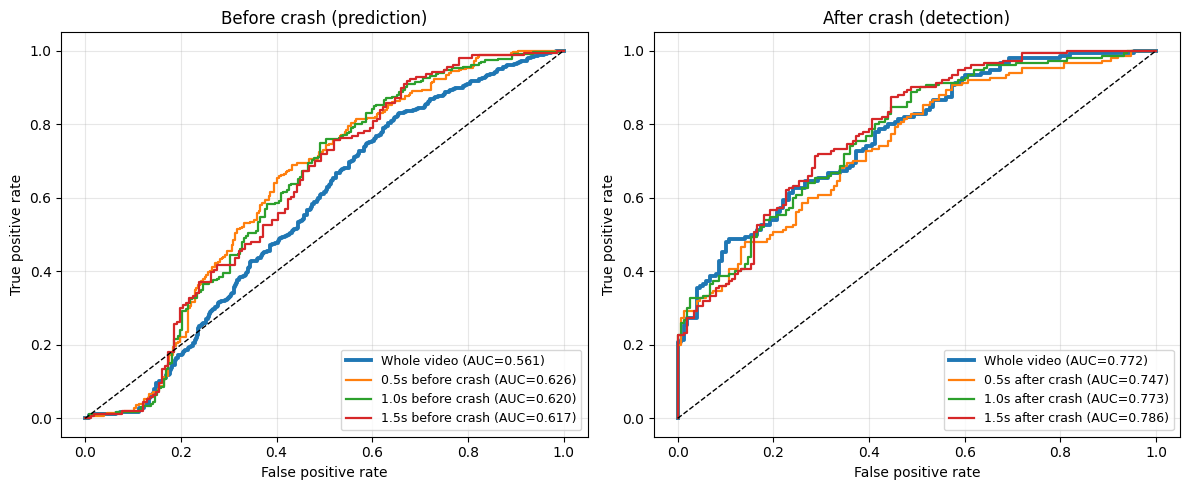

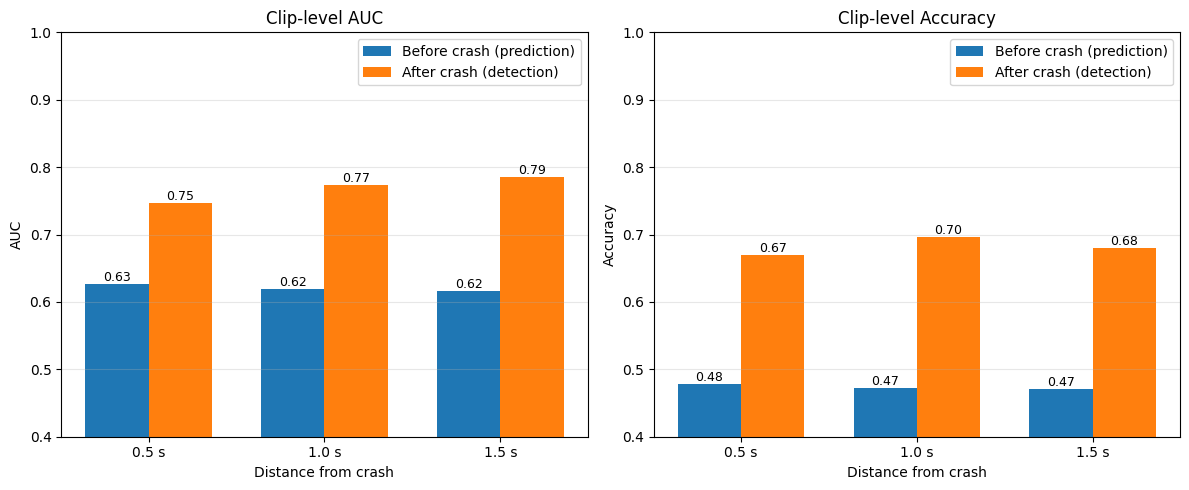

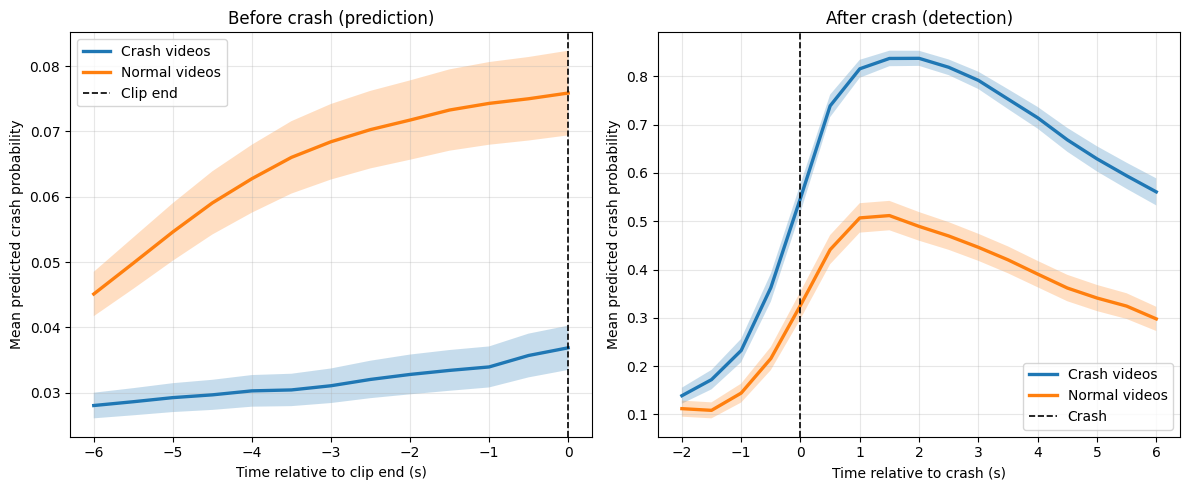

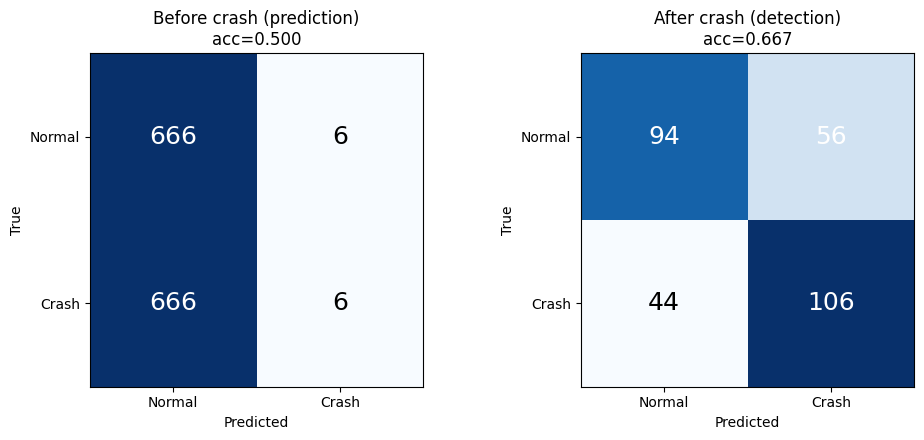

['confusion.png', 'final_results.csv', 'clip_metrics.png', 'final_before.png', 'results.csv', 'roc.png', 'aligned_curves.png']


In [50]:
R = {m: evaluate(m) for m in ("before", "detect")}

table = pd.DataFrame([r["row"] for r in R.values()]).set_index("mode")
table = table.drop(columns="agg").round(3)
print(table.T.to_string())
table.to_csv(f"{FIG_DIR}/results.csv")

plot_roc(R)
plot_clip_bars(R)
plot_aligned(R)
plot_confusion(R)
print(os.listdir(FIG_DIR))

<div dir="rtl" style="text-align: right;">

## اجرای مدل‌ها و بررسی نتایج نهایی

در این مرحله تمام مراحل آموزش و ارزیابی را برای دو حالت Prediction و Detection اجرا می‌کنیم.

ابتدا مدل برای هر حالت با ۵ مقدار مختلف Seed آموزش داده می‌شود و سپس خروجی مدل‌ها میانگین‌گیری می‌شود.

پس از پایان ارزیابی، معیارهای عملکرد دو مدل در قالب یک جدول نمایش داده می‌شوند و نتایج نیز در فایل CSV ذخیره می‌شوند.

**تحلیل نتایج آزمایش**

برای مقایسه عملکرد دو وظیفه، نتایج به‌دست‌آمده به شرح زیر است:

| معیار | Prediction (Before) | Detection (After) |
|---|---:|---:|
| Video AUC | 0.561 | 0.772 |
| Video AP | 0.505 | 0.790 |
| Video Accuracy | 0.500 | 0.667 |
| AUC (Max) | 0.555 | 0.771 |
| AUC (Top-3) | 0.561 | 0.772 |

**۱. تحلیل پیش‌بینی قبل از تصادف**

مقدار AUC برابر با 0.561 نشان می‌دهد که مدل در پیش‌بینی وقوع تصادف قبل از رخ دادن آن، عملکرد محدودی داشته است.

همچنین Accuracy برابر با 0.500 نشان می‌دهد که مدل در این آزمایش نتوانسته عملکرد مناسبی در طبقه‌بندی نهایی ویدئوها ارائه دهد.

این نتیجه نشان می‌دهد شناسایی الگوهای منتهی به تصادف پیش از وقوع آن، مسئله دشوارتری برای مدل بوده است.

**۲. تحلیل تشخیص بعد از تصادف**

در حالت Detection مقدار AUC به 0.772 و Average Precision به 0.790 رسیده است.

همچنین Accuracy برابر با 0.667 است که نشان‌دهنده عملکرد بهتر مدل در تشخیص تصادف پس از وقوع آن نسبت به پیش‌بینی قبل از وقوع است.

این تفاوت منطقی است؛ زیرا پس از وقوع تصادف، تغییرات تصویری مشخص‌تری در صحنه ایجاد می‌شوند که می‌توانند به شناسایی بهتر الگوها توسط شبکه کمک کنند.

**۳. تحلیل عملکرد زمانی**

در حالت Detection، بیشترین AUC در فاصله ۱٫۵ ثانیه بعد از تصادف برابر با 0.786 به دست آمده است.

در حالت Prediction، مقادیر AUC در فاصله‌های زمانی مختلف تقریباً ثابت و در محدوده 0.617 تا 0.626 قرار دارند.

این موضوع نشان می‌دهد مدل در تشخیص نشانه‌های پس از تصادف موفق‌تر از شناسایی نشانه‌های پیش از وقوع آن بوده است.

**۴. نتیجه‌گیری**

با توجه به نتایج، مدل ChainLSTM در تشخیص تصادف پس از وقوع آن عملکرد بهتری نسبت به پیش‌بینی تصادف قبل از وقوع نشان داده است.

بنابراین، معماری پیاده‌سازی‌شده در شرایط فعلی برای تشخیص وقوع تصادف مناسب‌تر از پیش‌بینی زودهنگام آن عمل می‌کند.

</div>